# Évaluation inter-jeux et transfert d'apprentissage : CICIDS2017 ↔ CSE-CIC-IDS2018

Ce notebook prolonge `project.ipynb`. Il répond à trois questions :

1. **Les scores tiennent-ils sur un autre réseau ?** Un modèle entraîné sur CICIDS2017 est testé sur CSE-CIC-IDS2018 (et inversement), sans transfert.
2. **Le pré-entraînement sur CSE-CIC-IDS2018 aide-t-il quand on dispose de peu de données étiquetées de CICIDS2017 ?** Comparaison « depuis zéro » / « pré-entraîné puis affiné » pour plusieurs tailles de jeu d'entraînement.
3. **Cela aide-t-il la classe Bots**, le point faible du projet principal ?

**Précautions méthodologiques**
- **Classes communes** : *Port Scanning* n'existe pas dans CSE-CIC-IDS2018, et *Infiltration* n'est pas utilisée. Les comparaisons inter-jeux portent sur 6 classes : Bots, Brute Force, DDoS, DoS, Normal Traffic, Web Attacks.
- **Variables communes** : les noms de colonnes diffèrent entre les deux jeux ; on renomme puis on garde l'intersection.
- **`Destination Port` est exclu** : variable propre à chaque jeu (raccourci possible).
- **Le test de CICIDS2017 est le même que dans `project.ipynb`** (même `random_state`, même stratification) et n'est jamais utilisé pour entraîner ou choisir.
- Les proportions de classes de CSE-CIC-IDS2018 sont modifiées (sous-échantillonnage du trafic normal) : on compare des **rappels par classe** et le macro-F1, pas l'accuracy.

## 1. Configuration

In [1]:
import glob
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier

SEED = 42
CSV_2017 = "cicids2017_cleaned.csv"          # same file as project.ipynb
DIR_2018 = "cse-cic-ids2018"                 # folder with the raw CSV files (Processed Traffic Data for ML Algorithms)
PARQUET_2018 = "cicids2018_common.parquet"   # compact file created in section 2 (done once)
BENIGN_FRAC = 0.10                           # keep 10 % of 2018 benign flows; ALL attack flows are kept
DROP_FEATURES = ["Destination Port"]         # dataset-specific shortcut, excluded everywhere below
SHARED_CLASSES = ["Bots", "Brute Force", "DDoS", "DoS", "Normal Traffic", "Web Attacks"]
sns.set_theme(style="whitegrid")

## 2. Préparation de CSE-CIC-IDS2018 (à exécuter une seule fois)

Les fichiers CSV représentent environ 6 Go (quelques dizaines de millions de valeurs par fichier) : on les lit **par morceaux**, en texte, puis on convertit en nombres. Les lignes d'en-tête répétées dans les fichiers et les étiquettes inutilisées sont éliminées. On garde toutes les attaques et seulement une fraction du trafic normal, puis on enregistre un fichier **Parquet** compact (`float32`) pour ne plus relire les CSV.

Vérifier après conversion le nombre de variables communes : si peu de colonnes sont reconnues, compléter `RENAME_2018`.

In [2]:
# 2018 column names -> 2017 names (CICFlowMeter abbreviations). Columns not listed keep their name.
RENAME_2018 = {
    "Dst Port": "Destination Port",
    "Tot Fwd Pkts": "Total Fwd Packets", "Tot Bwd Pkts": "Total Backward Packets",
    "TotLen Fwd Pkts": "Total Length of Fwd Packets", "TotLen Bwd Pkts": "Total Length of Bwd Packets",
    "Fwd Pkt Len Max": "Fwd Packet Length Max", "Fwd Pkt Len Min": "Fwd Packet Length Min",
    "Fwd Pkt Len Mean": "Fwd Packet Length Mean", "Fwd Pkt Len Std": "Fwd Packet Length Std",
    "Bwd Pkt Len Max": "Bwd Packet Length Max", "Bwd Pkt Len Min": "Bwd Packet Length Min",
    "Bwd Pkt Len Mean": "Bwd Packet Length Mean", "Bwd Pkt Len Std": "Bwd Packet Length Std",
    "Flow Byts/s": "Flow Bytes/s", "Flow Pkts/s": "Flow Packets/s",
    "Fwd IAT Tot": "Fwd IAT Total", "Bwd IAT Tot": "Bwd IAT Total",
    "Fwd Header Len": "Fwd Header Length", "Bwd Header Len": "Bwd Header Length",
    "Fwd Pkts/s": "Fwd Packets/s", "Bwd Pkts/s": "Bwd Packets/s",
    "Pkt Len Min": "Min Packet Length", "Pkt Len Max": "Max Packet Length",
    "Pkt Len Mean": "Packet Length Mean", "Pkt Len Std": "Packet Length Std",
    "Pkt Len Var": "Packet Length Variance",
    "FIN Flag Cnt": "FIN Flag Count", "SYN Flag Cnt": "SYN Flag Count", "RST Flag Cnt": "RST Flag Count",
    "PSH Flag Cnt": "PSH Flag Count", "ACK Flag Cnt": "ACK Flag Count", "URG Flag Cnt": "URG Flag Count",
    "ECE Flag Cnt": "ECE Flag Count",
    "Pkt Size Avg": "Average Packet Size",
    "Fwd Seg Size Avg": "Avg Fwd Segment Size", "Bwd Seg Size Avg": "Avg Bwd Segment Size",
    "Fwd Byts/b Avg": "Fwd Avg Bytes/Bulk", "Fwd Pkts/b Avg": "Fwd Avg Packets/Bulk",
    "Fwd Blk Rate Avg": "Fwd Avg Bulk Rate",
    "Bwd Byts/b Avg": "Bwd Avg Bytes/Bulk", "Bwd Pkts/b Avg": "Bwd Avg Packets/Bulk",
    "Bwd Blk Rate Avg": "Bwd Avg Bulk Rate",
    "Subflow Fwd Pkts": "Subflow Fwd Packets", "Subflow Fwd Byts": "Subflow Fwd Bytes",
    "Subflow Bwd Pkts": "Subflow Bwd Packets", "Subflow Bwd Byts": "Subflow Bwd Bytes",
    "Init Fwd Win Byts": "Init_Win_bytes_forward", "Init Bwd Win Byts": "Init_Win_bytes_backward",
    "Fwd Act Data Pkts": "act_data_pkt_fwd", "Fwd Seg Size Min": "min_seg_size_forward",
}

def map_label_2018(s):
    """2018 label -> 2017 class name; None for repeated header rows and unused classes (e.g. Infiltration)."""
    if not isinstance(s, str):
        return None
    t = s.strip().lower()
    if t == "benign":
        return "Normal Traffic"
    if t == "bot":
        return "Bots"
    if "ftp" in t or "ssh" in t:
        return "Brute Force"
    if "brute force" in t or "xss" in t or "sql" in t:
        return "Web Attacks"
    if "ddos" in t:
        return "DDoS"
    if "dos" in t:
        return "DoS"
    return None

def convert_2018(dir_2018=DIR_2018, out=PARQUET_2018, benign_frac=BENIGN_FRAC, chunksize=200_000):
    cols_2017 = [c for c in pd.read_csv(CSV_2017, nrows=0).columns if c != "Attack Type"]
    keep_cols = [c for c in cols_2017 if c not in DROP_FEATURES]
    rng = np.random.default_rng(SEED)
    parts, total = [], 0
    files = sorted(glob.glob(os.path.join(dir_2018, "*.csv")))
    assert files, f"no CSV found in {dir_2018!r}"
    for path in files:
        for chunk in pd.read_csv(path, dtype=str, chunksize=chunksize, low_memory=False):
            chunk.columns = [c.strip() for c in chunk.columns]
            chunk = chunk.rename(columns=RENAME_2018)
            total += len(chunk)
            label = chunk["Label"].map(map_label_2018)
            keep = label.notna().to_numpy().copy()   # copy: arrays from pandas 3 are read-only
            if benign_frac < 1:
                benign = (label == "Normal Traffic").to_numpy()
                keep = keep & (~benign | (rng.random(len(chunk)) < benign_frac))
            chunk, label = chunk[keep], label[keep]
            present = [c for c in keep_cols if c in chunk.columns]
            feats = chunk[present].apply(pd.to_numeric, errors="coerce").astype("float32")
            feats["Attack Type"] = label.to_numpy()
            parts.append(feats)
        print(os.path.basename(path), "done")
    df18 = pd.concat(parts, ignore_index=True)
    df18.replace([np.inf, -np.inf], np.nan).to_parquet(out, index=False)
    print(f"{total:,} rows read -> {len(df18):,} kept; saved to {out}")
    return df18

if not os.path.exists(PARQUET_2018):
    convert_2018()

## 3. Chargement et alignement des variables

In [3]:
df17 = pd.read_csv(CSV_2017)
df18 = pd.read_parquet(PARQUET_2018)

common = [c for c in df17.columns
          if c in df18.columns and c != "Attack Type" and c not in DROP_FEATURES]
print(f"{len(common)} common features")
print("2017 features missing in 2018 (check RENAME_2018 if this list is long):",
      sorted(set(df17.columns) - set(df18.columns) - {"Attack Type"} - set(DROP_FEATURES)))

def prep(df):
    X = df[common].replace([np.inf, -np.inf], np.nan).fillna(0).astype("float32")
    return X, df["Attack Type"].reset_index(drop=True)

X17, y17 = prep(df17)
X18, y18 = prep(df18)
del df17, df18

print("\n2017 classes:\n", y17.value_counts().to_string())
print("\n2018 classes:\n", y18.value_counts().to_string())

# Same split as project.ipynb for 2017 (same random_state + stratification => same test rows)
X17_tr, X17_te, y17_tr, y17_te = train_test_split(X17, y17, test_size=0.2, random_state=SEED, stratify=y17)
X18_tr, X18_te, y18_tr, y18_te = train_test_split(X18, y18, test_size=0.2, random_state=SEED, stratify=y18)
tgt_classes = sorted(y17.unique())          # 7 classes (target)
d = len(common)

51 common features
2017 features missing in 2018 (check RENAME_2018 if this list is long): []

2017 classes:
 Attack Type
Normal Traffic    2095057
DoS                193745
DDoS               128014
Port Scanning       90694
Brute Force          9150
Web Attacks          2143
Bots                 1948

2018 classes:
 Attack Type
Normal Traffic    1346873
DDoS              1263933
DoS                654300
Brute Force        380949
Bots               286191
Web Attacks           928


## 4. Évaluation inter-jeux (sans transfert)

On entraîne XGBoost (mêmes poids `sqrt` que dans le projet principal) sur un jeu, puis on le teste sur l'autre. La comparaison **dans le jeu** et **entre jeux** mesure directement le décalage de domaine. Une chute importante n'est pas un échec : c'est le résultat qui justifie le transfert.

In [4]:
XGB_PARAMS = {"objective": "multi:softprob", "eval_metric": "mlogloss", "n_estimators": 200, "max_depth": 6,
                  "learning_rate": 0.1, "subsample": 0.8, "colsample_bytree": 0.8, "tree_method": "hist",
                  "n_jobs": -1, "random_state": SEED}

def sqrt_weights(y):
    cnt = y.value_counts()
    return y.map(((cnt.max() / cnt) ** 0.5).to_dict()).to_numpy()

def fit_xgb(X, y, classes):
    le = LabelEncoder().fit(classes)
    model = XGBClassifier(**XGB_PARAMS).fit(X, le.transform(y), sample_weight=sqrt_weights(y))
    return model, le

def predict_xgb(model, le, X):
    return le.inverse_transform(model.predict(X).astype(int))

def evaluate_shared(y_true, y_pred, name):
    """Metrics restricted to the rows of the SHARED classes."""
    yt, yp = np.asarray(y_true), np.asarray(y_pred)
    m = np.isin(yt, SHARED_CLASSES)
    yt, yp = yt[m], yp[m]
    _, rc, f1, _ = precision_recall_fscore_support(yt, yp, labels=SHARED_CLASSES, zero_division=0)
    atk = yt != "Normal Traffic"
    return {"setting": name, "macro F1 (shared)": f1.mean(),
            **{f"recall {c}": r for c, r in zip(SHARED_CLASSES, rc)},
            "FN": int((atk & (yp == "Normal Traffic")).sum()),
            "FA": int((~atk & (yp != "Normal Traffic")).sum())}

m17, le17 = fit_xgb(X17_tr, y17_tr, tgt_classes)
m18, le18 = fit_xgb(X18_tr, y18_tr, SHARED_CLASSES)

zero_shot = pd.DataFrame([
    evaluate_shared(y17_te, predict_xgb(m17, le17, X17_te), "train 2017 -> test 2017 (same dataset)"),
    evaluate_shared(y18_te, predict_xgb(m17, le17, X18_te), "train 2017 -> test 2018 (other dataset)"),
    evaluate_shared(y18_te, predict_xgb(m18, le18, X18_te), "train 2018 -> test 2018 (same dataset)"),
    evaluate_shared(y17_te, predict_xgb(m18, le18, X17_te), "train 2018 -> test 2017 (other dataset)"),
]).set_index("setting").round(3)
zero_shot

,macro F1 (shared),recall Bots,recall Brute Force,recall DDoS,recall DoS,recall Normal Traffic,recall Web Attacks,FN,FA
setting,,,,,,,,,
train 2017 -> test 2017 (same dataset),0.962,0.974,0.998,1.000,1.000,0.999,0.998,25,540
train 2017 -> test 2018 (other dataset),0.091,0.000,0.000,0.000,0.019,1.000,0.000,514812,103
train 2018 -> test 2018 (same dataset),0.934,1.000,0.957,1.000,0.885,0.999,0.941,52,222
train 2018 -> test 2017 (other dataset),0.264,0.188,0.001,0.197,0.057,0.994,0.000,59440,2511


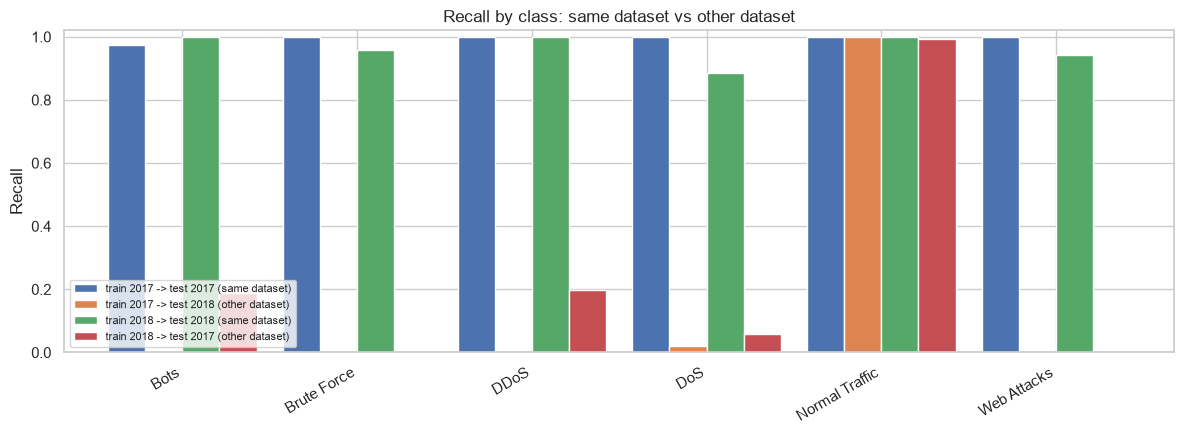

In [5]:
# Recall by class, same-dataset vs other-dataset
recall_cols = [c for c in zero_shot.columns if c.startswith("recall ")]
ax = zero_shot[recall_cols].rename(columns=lambda c: c.replace("recall ", "")).T.plot(
    kind="bar", figsize=(12, 4.5), ylim=(0, 1.02), width=0.85)
ax.set_title("Recall by class: same dataset vs other dataset")
ax.set_ylabel("Recall")
plt.xticks(rotation=30, ha="right")
plt.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

### Évaluation inter-datasets

Les résultats de l'évaluation inter-datasets révèlent une dégradation importante des performances par rapport aux expérimentations réalisées sur un même dataset. Alors que les modèles obtiennent des scores Macro F1 de 0,962 sur CIC-IDS2017 et de 0,934 sur CIC-IDS2018, ces scores chutent respectivement à 0,091 et 0,264 lors de l'évaluation sur l'autre dataset.

Cette dégradation est particulièrement visible au niveau de la détection des attaques. Dans l'expérience CIC-IDS2017 → CIC-IDS2018, le modèle atteint un Recall de 1,000 pour le trafic normal, mais échoue à détecter la majorité des catégories d'attaques.

Ces résultats mettent en évidence une faible capacité de généralisation des modèles entre différents environnements de données. Ce phénomène pourrait notamment s'expliquer par des différences dans les distributions du trafic réseau, les caractéristiques des attaques et les conditions de collecte des données.

### Diagnostic du décalage entre les deux jeux

L'effondrement ci-dessus peut venir d'un vrai décalage de domaine ou d'une différence de traitement des variables (échelle, définition). Trois contrôles : (1) échelle des variables sur le trafic normal des deux jeux, (2) un classifieur capable de distinguer 2017 de 2018 sur du trafic normal uniquement, (3) effet du retrait des variables les plus propres à chaque jeu sur le test 2017 → 2018.

In [6]:
# 1) Scale check on Normal traffic only: do the same features live on the same scale in both datasets?
N = 100_000
n17 = X17[y17 == "Normal Traffic"].sample(N, random_state=SEED)
n18 = X18[y18 == "Normal Traffic"].sample(N, random_state=SEED)
q = pd.DataFrame({"median 2017": n17.median(), "median 2018": n18.median(),
                  "p99 2017": n17.quantile(0.99), "p99 2018": n18.quantile(0.99)})
q["log10 ratio (median)"] = np.log10((q["median 2018"].abs() + 1e-9) / (q["median 2017"].abs() + 1e-9))
display(q.reindex(q["log10 ratio (median)"].abs().sort_values(ascending=False).index).head(15).round(3))
display(X17.describe().T[["min", "max"]].head(10))   # a 2017 file scaled to [0,1] or standardized shows up here

,median 2017,median 2018,p99 2017,p99 2018,log10 ratio (median)
Fwd Packet Length Min,6.000000,0.000000,8.100000e+01,6.600000e+01,-9.778
Bwd Packet Length Min,6.000000,0.000000,2.670000e+02,2.110000e+02,-9.778
Min Packet Length,6.000000,0.000000,7.800000e+01,6.500000e+01,-9.778
Bwd IAT Mean,3.000000,0.000000,5.900164e+07,1.068935e+07,-9.477
Bwd IAT Max,3.000000,0.000000,7.860000e+07,5.899822e+07,-9.477
Bwd IAT Total,3.000000,0.000000,1.178801e+08,1.178594e+08,-9.477
Bwd IAT Min,2.000000,0.000000,5.900000e+07,7.489704e+05,-9.301
Init_Win_bytes_backward,-1.000000,0.000000,6.368604e+04,6.395300e+04,-9.000
Fwd IAT Total,4.000000,18128.000000,1.180000e+08,1.181690e+08,3.656
Fwd IAT Max,4.000000,17073.500000,8.410000e+07,8.629668e+07,3.630


,min,max
Flow Duration,-13.0,1.200000e+08
Total Fwd Packets,1.0,2.197590e+05
Total Length of Fwd Packets,0.0,1.290000e+07
Fwd Packet Length Max,0.0,2.482000e+04
Fwd Packet Length Min,0.0,2.325000e+03
Fwd Packet Length Mean,0.0,5.940857e+03
Fwd Packet Length Std,0.0,7.125597e+03
Bwd Packet Length Max,0.0,1.953000e+04
Bwd Packet Length Min,0.0,2.896000e+03
Bwd Packet Length Mean,0.0,5.800500e+03


In [7]:
# 2) Domain classifier: can a model tell 2017 from 2018 using Normal traffic alone?
from sklearn.metrics import roc_auc_score

S = pd.concat([n17, n18])
dl = np.r_[np.zeros(N), np.ones(N)]
S_tr, S_te, d_tr, d_te = train_test_split(S, dl, test_size=0.3, random_state=SEED, stratify=dl)
dom = XGBClassifier(n_estimators=100, max_depth=4, n_jobs=-1, random_state=SEED).fit(S_tr, d_tr)
print("AUC 2017 vs 2018 (Normal only):", round(roc_auc_score(d_te, dom.predict_proba(S_te)[:, 1]), 3))
imp_dom = pd.Series(dom.feature_importances_, index=S.columns).sort_values(ascending=False)
display(imp_dom.head(10).round(3))

AUC 2017 vs 2018 (Normal only): 0.999


Fwd Packet Length Min    0.304
min_seg_size_forward     0.160
Bwd Packet Length Min    0.080
Max Packet Length        0.054
Fwd Packet Length Std    0.045
Min Packet Length        0.035
Fwd IAT Std              0.032
Packet Length Std        0.029
Average Packet Size      0.027
Bwd Header Length        0.027
dtype: float32

In [8]:
# 3) Drop the most dataset-specific features and repeat 2017 -> 2018
rows = []
for k in [0, 5, 10, 20]:
    keep = [c for c in common if c not in imp_dom.head(k).index]
    m, le_k = fit_xgb(X17_tr[keep], y17_tr, tgt_classes)
    rows.append(evaluate_shared(y18_te, predict_xgb(m, le_k, X18_te[keep]), f"drop top-{k} features"))
pd.DataFrame(rows).set_index("setting")[["macro F1 (shared)", "recall Bots", "FN"]].round(3)

,macro F1 (shared),recall Bots,FN
setting,,,
drop top-0 features,0.091,0.0,514812
drop top-5 features,0.090,0.0,515175
drop top-10 features,0.090,0.0,515160
drop top-20 features,0.158,0.0,457197


## 5. Transfert par affinage (réseau de neurones)

Le transfert par paramètres (*fine-tuning*) suppose un modèle dont on peut réutiliser les poids : un **MLP**. Les arbres (Random Forest, XGBoost) ne s'y prêtent pas directement. Protocole :

1. **Pré-entraînement** d'un MLP sur CSE-CIC-IDS2018 (6 classes).
2. **Affinage** sur une fraction de CICIDS2017 : nouveau « head » à 7 classes (Port Scanning inclus), poids du corps copiés. Phase 1 : corps gelé, seul le head apprend. Phase 2 : tout est dégelé avec un pas d'apprentissage plus petit.
3. **Référence** : même MLP entraîné **depuis zéro** sur la même fraction.
4. Mesure sur le **test de CICIDS2017** (7 classes) pour plusieurs fractions, avec plusieurs répétitions.

Deux méthodes à base d'arbres servent de repères : XGBoost depuis zéro, et XGBoost qui reçoit en plus les **probabilités du modèle source** (2018) comme variables (transfert par représentation).

Le prétraitement (log signé puis standardisation) est **ajusté sur le jeu source uniquement** et réutilisé tel quel pour la cible, afin que les poids pré-entraînés gardent leur sens.

In [9]:
import torch
from torch import nn

torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

def signed_log1p(a):
    return np.sign(a) * np.log1p(np.abs(a))

scaler = StandardScaler().fit(signed_log1p(X18_tr.to_numpy()))      # fitted on the SOURCE only

def to_tensor(X):
    Z = scaler.transform(signed_log1p(X.to_numpy()))
    return torch.tensor(np.clip(Z, -10, 10), dtype=torch.float32)

class MLP(nn.Module):
    def __init__(self, d_in, n_classes, hidden=(256, 128), p=0.1):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(d_in, hidden[0]), nn.ReLU(), nn.Dropout(p),
                                  nn.Linear(hidden[0], hidden[1]), nn.ReLU(), nn.Dropout(p))
        self.head = nn.Linear(hidden[1], n_classes)
    def forward(self, x):
        return self.head(self.body(x))

def class_weights(y, idx):
    cnt = y.value_counts().reindex(list(idx), fill_value=0).astype(float)
    return ((cnt.max() / cnt.clip(lower=1)) ** 0.5).to_numpy()

def train_mlp(model, X, y_idx, weights, epochs, lr, params=None, batch=None):
    model.to(DEVICE).train()
    batch = batch or min(4096, max(64, len(X) // 20))      # >= ~20 steps per epoch, even on small subsets
    opt = torch.optim.Adam(params if params is not None else model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE))
    ds = torch.utils.data.TensorDataset(X, torch.as_tensor(np.array(y_idx), dtype=torch.long))
    dl = torch.utils.data.DataLoader(ds, batch_size=batch, shuffle=True)
    for _ in range(epochs):
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()
    return model

@torch.no_grad()
def predict_mlp(model, X, batch=65536):
    model.eval().to(DEVICE)
    out = [model(X[i:i + batch].to(DEVICE)).argmax(1).cpu() for i in range(0, len(X), batch)]
    return torch.cat(out).numpy()

idx17 = {c: i for i, c in enumerate(tgt_classes)}                 # 7-class index space (target)
idx18 = {c: i for i, c in enumerate(sorted(SHARED_CLASSES))}      # 6-class index space (source)

# 1) pre-training on 2018
EPOCHS_PRETRAIN = 5
t0 = time.time()
src_mlp = MLP(d, len(idx18))
train_mlp(src_mlp, to_tensor(X18_tr), y18_tr.map(idx18).to_numpy(), class_weights(y18_tr, idx18),
          epochs=EPOCHS_PRETRAIN, lr=1e-3)
print(f"pre-training done in {time.time() - t0:.0f} s")

# quick check: the pre-trained network on the 2018 test set
pred18 = np.array(sorted(SHARED_CLASSES))[predict_mlp(src_mlp, to_tensor(X18_te))]
print(pd.DataFrame([evaluate_shared(y18_te, pred18, "MLP pre-trained, test 2018")]).set_index("setting").round(3).T.to_string())

device: cpu
pre-training done in 312 s
setting                MLP pre-trained, test 2018
macro F1 (shared)                           0.862
recall Bots                                 0.999
recall Brute Force                          0.947
recall DDoS                                 0.998
recall DoS                                  0.877
recall Normal Traffic                       0.993
recall Web Attacks                          0.800
FN                                        540.000
FA                                       1784.000


### Courbe d'apprentissage : depuis zéro vs pré-entraîné

On fait varier la fraction de CICIDS2017 utilisée pour l'entraînement (sous-échantillon stratifié) et on répète chaque point plusieurs fois avec des sous-échantillons différents. **Le transfert est utile si la courbe « pré-entraîné » est au-dessus de « depuis zéro » pour les petites fractions** ; l'écart doit dépasser l'écart-type entre répétitions pour être jugé réel. Si la courbe pré-entraînée est en dessous, c'est un **transfert négatif** : à rapporter tel quel.

Pour aller plus vite : réduire `N_REPEATS`, `FRACTIONS` ou `n_estimators` ; utiliser un GPU (Colab) accélère surtout les MLP.

In [10]:
FRACTIONS = [0.005, 0.02, 0.1, 0.5]
N_REPEATS = 3
EPOCHS_SCRATCH, EPOCHS_HEAD, EPOCHS_FT = 15, 3, 8

le_t = LabelEncoder().fit(tgt_classes)
Xte_t = to_tensor(X17_te)
P_te = m18.predict_proba(X17_te)                       # source-model probabilities on the target test rows
Xte_stack = np.hstack([X17_te.to_numpy(), P_te])
classes_arr = np.array(tgt_classes)
bots_pos = tgt_classes.index("Bots")

def eval_target(pred, method, frac, rep):
    yt, yp = y17_te.to_numpy(), np.asarray(pred)
    _, rc, f1, _ = precision_recall_fscore_support(yt, yp, labels=tgt_classes, zero_division=0)
    atk = yt != "Normal Traffic"
    return {"method": method, "fraction": frac, "repeat": rep, "macro F1": f1.mean(),
            "Bots recall": rc[bots_pos], "FN": int((atk & (yp == "Normal Traffic")).sum())}

rows = []
for frac in FRACTIONS:
    for rep in range(N_REPEATS):
        Xs, _, ys, _ = train_test_split(X17_tr, y17_tr, train_size=frac, stratify=y17_tr, random_state=SEED + rep)
        if set(ys) != set(tgt_classes):
            print(f"skip fraction {frac}, repeat {rep}: a class is missing from the subset")
            continue
        ys_idx, cw, Xs_t = ys.map(idx17).to_numpy(), class_weights(ys, idx17), to_tensor(Xs)

        # (1) MLP from scratch
        torch.manual_seed(SEED + rep)
        m = train_mlp(MLP(d, len(tgt_classes)), Xs_t, ys_idx, cw, EPOCHS_SCRATCH, 1e-3)
        rows.append(eval_target(classes_arr[predict_mlp(m, Xte_t := Xte_t)], "MLP from scratch", frac, rep))

        # (2) MLP pre-trained on 2018, then fine-tuned (new 7-class head, body copied)
        torch.manual_seed(SEED + rep)
        m = MLP(d, len(tgt_classes))
        m.body.load_state_dict(src_mlp.body.state_dict())
        for p in m.body.parameters():
            p.requires_grad = False
        train_mlp(m, Xs_t, ys_idx, cw, EPOCHS_HEAD, 1e-3, params=m.head.parameters())    # phase 1: head only
        for p in m.body.parameters():
            p.requires_grad = True
        train_mlp(m, Xs_t, ys_idx, cw, EPOCHS_FT, 1e-4)                                   # phase 2: everything
        rows.append(eval_target(classes_arr[predict_mlp(m, Xte_t)], "MLP pre-trained + fine-tuned", frac, rep))

        # (3) XGBoost from scratch
        xs = XGBClassifier(**XGB_PARAMS).fit(Xs, le_t.transform(ys), sample_weight=sqrt_weights(ys))
        rows.append(eval_target(le_t.inverse_transform(xs.predict(X17_te).astype(int)), "XGBoost from scratch", frac, rep))

        # (4) XGBoost + source-model probabilities as extra features
        Xs_stack = np.hstack([Xs.to_numpy(), m18.predict_proba(Xs)])
        xs2 = XGBClassifier(**XGB_PARAMS).fit(Xs_stack, le_t.transform(ys), sample_weight=sqrt_weights(ys))
        rows.append(eval_target(le_t.inverse_transform(xs2.predict(Xte_stack).astype(int)),
                                "XGBoost + source probabilities", frac, rep))
        print(f"fraction {frac}, repeat {rep + 1}/{N_REPEATS} done")

lc = pd.DataFrame(rows)
summary = lc.groupby(["method", "fraction"])[["macro F1", "Bots recall", "FN"]].agg(["mean", "std"]).round(3)
summary

fraction 0.005, repeat 1/3 done
fraction 0.005, repeat 2/3 done
fraction 0.005, repeat 3/3 done
fraction 0.02, repeat 1/3 done
fraction 0.02, repeat 2/3 done
fraction 0.02, repeat 3/3 done
fraction 0.1, repeat 1/3 done
fraction 0.1, repeat 2/3 done
fraction 0.1, repeat 3/3 done
fraction 0.5, repeat 1/3 done
fraction 0.5, repeat 2/3 done
fraction 0.5, repeat 3/3 done


macro F1        Bots recall         \
                                            mean    std        mean    std   
method                         fraction                                      
MLP from scratch               0.005       0.724  0.024       0.392  0.151   
                               0.020       0.753  0.037       0.676  0.158   
                               0.100       0.902  0.002       0.608  0.009   
                               0.500       0.884  0.033       0.829  0.181   
MLP pre-trained + fine-tuned   0.005       0.637  0.009       0.098  0.169   
                               0.020       0.698  0.027       0.095  0.165   
                               0.100       0.753  0.003       0.597  0.009   
                               0.500       0.837  0.021       0.854  0.026   
XGBoost + source probabilities 0.005       0.890  0.017       0.294  0.089   
                               0.020       0.942  0.008       0.657  0.057   
                               0.100       0.963  0.001       0.838  0.004   
                               0.500       0.964  0.000       0.927  0.006   
XGBoost from scratch           0.005       0.903  0.014       0.370  0.077   
                               0.020       0.950  0.004       0.725  0.040   
                               0.100       0.963  0.002       0.853  0.017   
                               0.500       0.964  0.000       0.938  0.004   

                                               FN           
                                             mean      std  
method                         fraction                     
MLP from scratch               0.005     2248.000  575.010  
                               0.020     1432.333  337.506  
                               0.100      901.333   62.820  
                               0.500      458.667   87.306  
MLP pre-trained + fine-tuned   0.005     6389.333  698.965  
                               0.020     5773.000  625.480  
                               0.100     1854.333   22.189  
                               0.500      716.333   15.308  
XGBoost + source probabilities 0.005     1060.000   95.126  
                               0.020      489.667   58.620  
                               0.100      177.333    7.506  
                               0.500       64.333    4.509  
XGBoost from scratch           0.005      979.667  198.707  
                               0.020      414.667   76.950  
                               0.100      142.667    8.021  
                               0.500       53.333    4.509

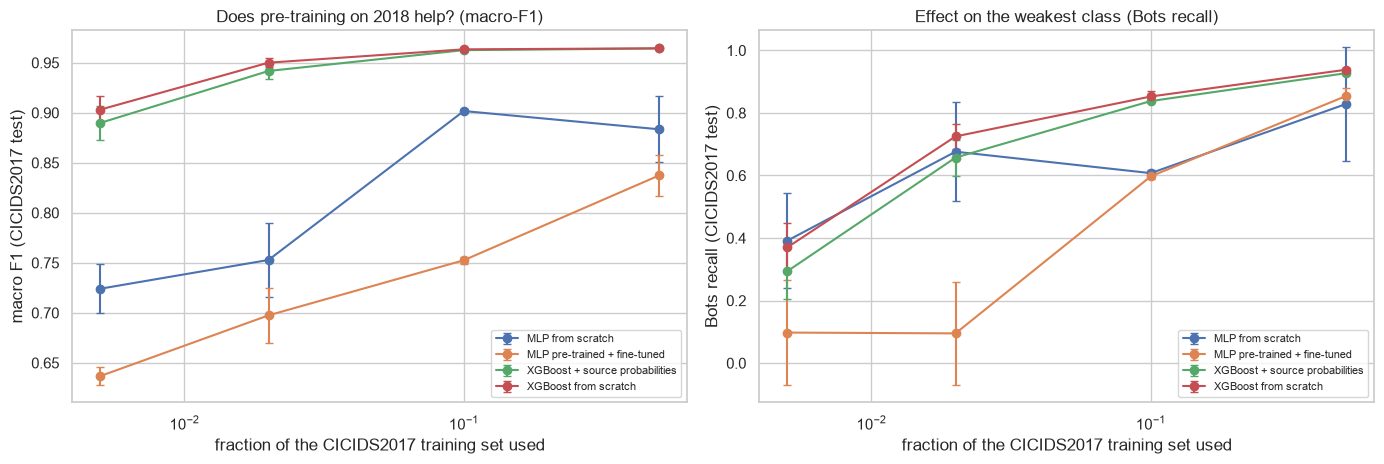

,gain macro-F1 (mean),std
fraction,,
0.005,-0.0873,0.0226
0.020,-0.0554,0.0630
0.100,-0.1492,0.0040
0.500,-0.0462,0.0269


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric in zip(axes, ["macro F1", "Bots recall"]):
    for method, g in lc.groupby("method"):
        s = g.groupby("fraction")[metric].agg(["mean", "std"]).fillna(0)
        ax.errorbar(s.index, s["mean"], yerr=s["std"], marker="o", capsize=3, label=method)
    ax.set_xscale("log")
    ax.set_xlabel("fraction of the CICIDS2017 training set used")
    ax.set_ylabel(metric + " (CICIDS2017 test)")
    ax.legend(fontsize=8)
axes[0].set_title("Does pre-training on 2018 help? (macro-F1)")
axes[1].set_title("Effect on the weakest class (Bots recall)")
plt.tight_layout()
plt.show()

# paired gain from pre-training (same fraction and same subset)
piv = lc.pivot_table(index=["fraction", "repeat"], columns="method", values="macro F1")
gain = (piv["MLP pre-trained + fine-tuned"] - piv["MLP from scratch"]).groupby("fraction").agg(["mean", "std"]).round(4)
gain.columns = ["gain macro-F1 (mean)", "std"]
gain

## 6. Conclusion

### Résumé

Les modèles entraînés sur un jeu de données ne se généralisent pas à l'autre : XGBoost atteint un macro-F1 de 0,962 (CICIDS2017) et de 0,934 (CSE-CIC-IDS2018) sur son propre jeu, mais seulement 0,091 et 0,264 sur l'autre. Le pré-entraînement sur CSE-CIC-IDS2018 n'améliore pas les résultats sur CICIDS2017 et dégrade le MLP.

### 1. Décalage de domaine

Les scores sont calculés sur les 6 classes communes aux deux jeux (Port Scanning, absent de CSE-CIC-IDS2018, est exclu).

| Entraînement → test | Macro-F1 | Rappel Bots | Attaques manquées (FN) |
|---|---|---|---|
| 2017 → 2017 | 0,962 | 0,974 | 25 |
| 2017 → 2018 | 0,091 | 0,000 | 514 812 |
| 2018 → 2018 | 0,934 | 1,000 | 52 |
| 2018 → 2017 | 0,264 | 0,188 | 59 440 |

Entraîné sur 2017, le modèle classe environ 99,5 % des attaques de 2018 comme trafic normal : le rappel est nul pour Bots, Brute Force, DDoS et Web Attacks, et de 0,019 pour DoS. Dans l'autre sens, environ 89 % des attaques de 2017 sont manquées. Les scores élevés obtenus sur CICIDS2017 ne se généralisent donc pas à un autre jeu de données.

**Diagnostic.** Trois contrôles ont été réalisés.
- **Échelle des variables.** Les deux jeux sont sur la même échelle brute : les 99e centiles sont du même ordre de grandeur (environ 1,2·10⁸ pour `Fwd IAT Total`, 6,4·10⁴ pour `Init_Win_bytes_backward`), ce qui rend peu probable une normalisation différente d'un des fichiers. En revanche, le flux normal typique diffère : médiane de `Fwd Packet Length Min`, `Bwd Packet Length Min` et `Min Packet Length` égale à 6 en 2017 contre 0 en 2018, médiane de `Bwd IAT Total` de 3 contre 0, médiane de `Fwd IAT Total` de 4 contre environ 18 000, médiane de `Init_Win_bytes_backward` de −1 contre 0.
- **Classifieur de domaine.** Un classifieur entraîné à distinguer le trafic normal de 2017 de celui de 2018 atteint une AUC de 0,999 : les deux jeux sont presque parfaitement séparables avant même de considérer les attaques. L'importance est concentrée sur des variables de longueurs minimales de paquets et de segments (`Fwd Packet Length Min` 0,304, `min_seg_size_forward` 0,160, `Bwd Packet Length Min` 0,080).
- **Retrait des variables les plus spécifiques.** Retirer les 5 ou 10 premières ne change pas le test 2017 → 2018 (macro-F1 de 0,091 puis 0,090), et en retirer 20 sur 51 ne le porte qu'à 0,158, avec encore environ 88 % des attaques manquées et un rappel Bots nul.

Le décalage est donc diffus : il ne vient pas d'une différence d'échelle ni de quelques variables isolées, mais de la forme même des flux typiques. Nos données ne permettent pas de distinguer une différence de composition du trafic d'une différence de calcul des variables entre les deux captures.

### 2. Effet du pré-entraînement

Le pré-entraînement sur CSE-CIC-IDS2018 n'améliore pas les résultats sur CICIDS2017. Ce résultat est cohérent avec le décalage mesuré : si les variables ne se comportent pas de la même façon dans les deux jeux, les poids appris sur 2018 apportent peu à CICIDS2017.

- **MLP.** Le modèle pré-entraîné puis affiné est moins bon que le MLP entraîné depuis zéro pour toutes les fractions testées. Écart de macro-F1 apparié : −0,087 ± 0,023 à 0,5 %, −0,055 ± 0,063 à 2 %, −0,149 ± 0,004 à 10 %, −0,046 ± 0,027 à 50 %. L'écart est net à 0,5 % et 10 %, incertain à 2 % et à 50 % (3 répétitions seulement). Les attaques non détectées sont plus nombreuses à toutes les fractions (par exemple 716 contre 459 à 50 %).
- **XGBoost.** Fournir les probabilités du modèle source comme variables supplémentaires n'apporte aucun gain de macro-F1 (0,963 contre 0,963 à 10 % ; 0,964 contre 0,964 à 50 %) et augmente légèrement les attaques non détectées à 10 % et 50 % (177 contre 143 ; 64 contre 53).
- **Classe Bots.** Le pré-entraînement dégrade nettement le rappel aux petites fractions (0,10 contre 0,39 à 0,5 % ; 0,10 contre 0,68 à 2 %) et le rend équivalent à celui du MLP depuis zéro à 10 % et 50 % (0,60 contre 0,61 ; 0,85 contre 0,83, avec un écart-type de 0,18 pour le MLP depuis zéro).

### 3. Comparaison des modèles

XGBoost entraîné depuis zéro est le meilleur à toutes les fractions : macro-F1 de 0,950 avec 2 % des données, contre 0,884 pour le MLP avec 50 % (pour un MLP non optimisé, à architecture et nombre d'époques fixes). Son macro-F1 plafonne dès 10 % des données (0,963), mais le rappel Bots (0,853 → 0,938) et les attaques non détectées (143 → 53) progressent encore jusqu'à 50 % : la classe rare est le facteur limitant.

### 4. Implication pratique

Un modèle entraîné sur 2 % des données de CICIDS2017 (environ 40 000 flux) atteint un macro-F1 de 0,950 sur son propre test, contre 0,09 à 0,26 pour un modèle entraîné sur l'autre jeu en entier. Pour un déploiement réel, quelques données étiquetées du réseau visé valent donc beaucoup plus qu'un grand jeu public provenant d'un autre réseau.

### 5. Limites

- Les deux jeux viennent du même laboratoire, du même outil d'extraction et de familles d'attaques proches, et l'effondrement est pourtant massif : un réseau réel serait vraisemblablement encore plus éloigné.
- Les erreurs d'étiquetage connues dans les deux jeux et le sous-échantillonnage du trafic normal de 2018 (10 %) limitent l'interprétation ; les proportions de classes de 2018 ne sont pas celles du trafic réel.
- L'origine exacte du décalage (composition du trafic ou calcul des variables) reste indéterminée sans les captures de paquets.
- Trois répétitions seulement : les écarts-types sont peu précis.